# Ranking: nDCG and AUC do not agree, and neither agrees with itself

Calibration averages coincide. Ranking averages do not: micro, per-class and per-example nDCG
differ, and so do micro, macro and exemplar AUC. This notebook ranks three classifiers on *yeast*
under all of them, reads each gap as a covariance, and looks at the labels on which nDCG and AUC
disagree.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q "aggmetrics>=0.3" scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.multioutput import MultiOutputClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from aggmetrics.scores import ScoreMatrix

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10,
})

## Data and scores

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/yeast.npz"
local = Path("../data/yeast.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    X, Y = z["X"], z["Y"].astype(int)
print("examples, features, labels:", X.shape[0], X.shape[1], Y.shape[1])

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
    "kNN (k=10)": make_pipeline(StandardScaler(), KNeighborsClassifier(10)),
}

def out_of_fold_scores(model):
    """Scores in [0, 1] for every example, each from a model that did not see it."""
    P = np.zeros(Y.shape)
    for train, test in KFold(5, shuffle=True, random_state=0).split(X):
        fitted = MultiOutputClassifier(model).fit(X[train], Y[train])
        P[test] = np.column_stack([p[:, 1] for p in fitted.predict_proba(X[test])])
    return P

scores = {name: ScoreMatrix(Y, out_of_fold_scores(m)) for name, m in models.items()}

examples, features, labels: 2417 103 14


## Seven ways to score the same scores

nDCG is computed with mid-ranks for tied scores (`ties="average"`); the next section shows why.

In [4]:
from aggmetrics.scores import auc, ndcg, pooled_auc

rows = []
for name, sm in scores.items():
    rows.append({"model": name,
                 "nDCG micro": ndcg(sm, "micro", ties="average"),
                 "nDCG class": ndcg(sm, "macro", ties="average"),
                 "nDCG exemplar": ndcg(sm, "exemplar", ties="average"),
                 "AUC micro": auc(sm, "micro"), "AUC macro": auc(sm, "macro"),
                 "AUC exemplar": auc(sm, "exemplar"), "AUC pooled": pooled_auc(sm)})
table = pd.DataFrame(rows).set_index("model")
table.round(4)

,nDCG micro,nDCG class,nDCG exemplar,AUC micro,AUC macro,AUC exemplar,AUC pooled
model,,,,,,,
Logistic regression,0.8734,0.4406,0.8502,0.6787,0.6749,0.6857,0.8254
Random forest,0.8837,0.4299,0.8568,0.7146,0.7117,0.7209,0.8503
kNN (k=10),0.8364,0.4271,0.8143,0.6948,0.6779,0.7000,0.8345


In [5]:
for col in table.columns:
    print(f"{col:14s} best model: {table[col].idxmax()}")

nDCG micro     best model: Random forest
nDCG class     best model: Logistic regression
nDCG exemplar  best model: Random forest
AUC micro      best model: Random forest
AUC macro      best model: Random forest
AUC exemplar   best model: Random forest
AUC pooled     best model: Random forest


The random forest wins every column except per-class nDCG, where the logistic regression comes
first by a small margin: even the choice between two models can depend on the aggregation.
`AUC pooled` (scikit-learn's micro ROC-AUC, which compares a positive of one label with a negative
of another) is a different number from `AUC micro`.

## Ties decide the ranking

The kNN scores are multiples of 0.1, so many labels of an example tie. With the default `ties="min"`
every tied label gets the best rank of its group, which flatters the model, and nDCG can exceed 1.

In [6]:
knn = scores["kNN (k=10)"]
print("kNN micro-nDCG by tie convention:",
      {t: round(ndcg(knn, "micro", ties=t), 4) for t in ("min", "average", "ordinal")})
print("distinct scores per row, kNN:", np.mean([len(set(r)) for r in knn.P]).round(1), "of", Y.shape[1])

kNN micro-nDCG by tie convention: {'min': 1.0419, 'average': 0.8364, 'ordinal': 0.8781}
distinct scores per row, kNN: 6.1 of 14


Under mid-ranks, or an ordinal tie-break, the kNN advantage shrinks or disappears. State the tie
convention whenever scores are discrete (kNN, trees, rounded outputs).

## Each gap is a covariance

`auc_gaps` writes micro minus macro AUC as `Cov(n_j^+, AUC_j) / mean(n_j^+)`: micro-AUC weights
each label by its number of positives, so it is higher when the frequent labels are the easy ones.

In [7]:
from aggmetrics.scores import auc_gaps, ndcg_gaps

sm = scores["Random forest"]
g = auc_gaps(sm)
print("micro - macro AUC      :", round(g["micro_minus_macro"], 4))
print("Cov(n+, AUC_j)/mean n+ :", round(g["class_covariance"] / g["mean_positives"], 4))
print("largest contributions  :", np.argsort(-np.abs(g["class_contributions"]))[:3])

h = ndcg_gaps(sm, ties="average")
print("micro - exemplar nDCG  :", round(h["micro_minus_exemplar"], 4),
      "  = Cov / mean ideal DCG =", round(h["covariance"] / h["mean_ideal"], 4))

micro - macro AUC      : 0.0029
Cov(n+, AUC_j)/mean n+ : 0.0029
largest contributions  : [11 12  2]
micro - exemplar nDCG  : 0.0269   = Cov / mean ideal DCG = 0.0269


## Two questions about the same label

Per-class nDCG asks where label `j` sits among the labels of its positive examples. AUC asks
whether its positives outscore its negatives. A label can be good at one and bad at the other.

label pairs ordered oppositely by nDCG_j and AUC_j: 33 of 91  (tau = 0.275 )


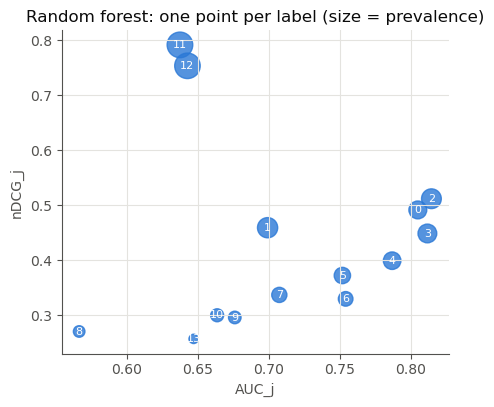

In [8]:
from aggmetrics.scores import ranking_duality

d = ranking_duality(sm, ties="average")
print("label pairs ordered oppositely by nDCG_j and AUC_j:", len(d["discordant"]),
      "of", d["compared"], " (tau =", round(d["tau"], 3), ")")

fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(d["auc"], d["ndcg"], s=40 + 400 * Y.mean(axis=0), color=BLUE, alpha=.8)
for j in range(Y.shape[1]):
    ax.annotate(str(j), (d["auc"][j], d["ndcg"][j]), fontsize=8, ha="center", va="center", color="white")
ax.set_xlabel("AUC_j"); ax.set_ylabel("nDCG_j")
ax.set_title("Random forest: one point per label (size = prevalence)")
plt.show()

The points are not on a line: the two families order the labels differently, so a "mean over
labels" of one is not a stand-in for the other.

## What the diagnostics say

In [9]:
from aggmetrics.scores import diagnose_scores

for f in diagnose_scores(sm, ties="average"):
    print(f)

[note] ndcg_no_collapse: micro-nDCG 0.8837, class mean 0.4299 and exemplar mean 0.8568 differ; micro - exemplar is Cov(IDCG_i, nDCG_i)/mean IDCG = +0.0269, and class 11 contributes most to micro - class
[note] auc_no_collapse: micro-AUC 0.7146, macro-AUC 0.7117 and exemplar mean 0.7209 differ; micro - macro is Cov(n_j^+, AUC_j)/mean n^+ = +0.0029
[note] pooled_auc_differs: pooled ROC-AUC (0.8503, scikit-learn's 'micro') differs from micro-AUC (0.7146): it compares positives of one class with negatives of another, so it depends on how the classes' scores are scaled
[note] ranking_duality: per-class nDCG and AUC order 33 of 91 label pairs oppositely (tau +0.275); nDCG asks where a label sits among the labels of its positives, AUC whether its positives outscore its negatives
[note] class_coupling: 2385 examples carry several labels, so replicating the positives of one label also replicates positives of others and moves their alpha, AUC and nDCG; brier_under_prior and the skew-invariance o

## What to take away

- State the tie convention. Min-rank can push nDCG above 1 for discrete scores.
- Name the aggregation. nDCG and AUC have three values each, and they can rank models differently.
- Do not report scikit-learn's micro ROC-AUC as "micro-AUC" of a multilabel problem: it is the pooled
  value, which depends on how the labels' scores are scaled.
- The gaps are explained by covariances (`auc_gaps`, `ndcg_gaps`), so you can say whether
  frequency or ease drives them.